# Motor de costos predictivos para la cotización de obras viales
**Maestría en Ciencia de Datos e Inteligencia Artificial · Caso INDUMAQ S.R.L. (Arequipa, Perú)**

Este cuaderno reproduce de principio a fin el experimento del informe: datos, análisis exploratorio, ajuste de
hiperparámetros, comparación de 12 modelos con validación walk-forward, intervalos conformales, pruebas de
significancia, ablación, explicabilidad (SHAP), monitoreo de deriva, pruebas de robustez y análisis económico.

**Cómo usarlo en Google Colab:** `Entorno de ejecución → Ejecutar todo`. Tarda entre 8 y 12 minutos en CPU.
Para usar los datos reales de la empresa, suba un CSV con el esquema de `data/plantilla_erp.csv` en la sección 1.

| Paso | Contenido |
|---|---|
| 0 | Instalación y código del paquete `mcp` |
| 1 | Datos: variables externas reales (Brent, USD/PEN) y costos internos |
| 2 | Análisis exploratorio |
| 3 | Ajuste de hiperparámetros (solo periodo de validación) |
| 4 | Validación walk-forward de 12 modelos |
| 5 | Métricas, pruebas DM-HLN con corrección de Holm, bootstrap y MCS |
| 6 | Contingencia y comparación con la línea de base |
| 7 | Ablación y explicabilidad SHAP |
| 8 | Monitoreo de deriva |
| 9 | Robustez y falsación |
| 10 | Análisis económico y Monte Carlo |

## 0. Instalación y código fuente

In [1]:
import sys, subprocess, importlib.util
paquetes = ["lightgbm", "arch", "chronos-forecasting", "xgboost", "statsmodels"]
faltan = [p for p in paquetes if importlib.util.find_spec(p.replace("-forecasting", "").replace("-", "_")) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
import os; os.makedirs("src/mcp", exist_ok=True); os.makedirs("data", exist_ok=True)

El paquete `mcp` se escribe en disco con las celdas siguientes, para que el código quede visible y versionado en el propio cuaderno.

In [2]:
%%writefile src/mcp/__init__.py
# Paquete mcp

Writing src/mcp/__init__.py


In [3]:
%%writefile src/mcp/config.py
"""Parámetros globales del experimento.

Todos los valores se fijan antes de mirar el periodo de prueba y no se modifican después.
"""
from pathlib import Path

RAIZ = Path(__file__).resolve().parents[2]
DATA = RAIZ / "data"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RESULTADOS / "figuras"
ARTEFACTOS = RAIZ / "artefactos"

SEMILLA = 2026          # semilla del generador sintético y de los modelos
H = 4                   # horizonte de predicción (semanas)
INICIO_VAL = 60         # primera semana (índice 0) con predicción fuera de muestra: validación
INICIO_TEST = 84        # primera semana del periodo de prueba (no se usa para ninguna decisión)
CUANTILES = (0.1, 0.5, 0.9)
ALPHA = 0.20            # 1 - cobertura nominal del intervalo P10-P90
GAMMA_ACI = 0.03        # tasa de aprendizaje de la calibración conformal adaptativa
VENTANA_CONFORMAL = 40  # puntajes de no conformidad usados por la calibración
CONTINGENCIA_BASE = 0.05  # práctica actual: contingencia fija por criterio
PISO_CONTINGENCIA = 0.01
FAMILIAS = ("costo_mac", "costo_tierras")
NOMBRE_FAMILIA = {"costo_mac": "MAC (S/ por t)", "costo_tierras": "Movimiento de tierras (S/ por m³)"}

for _p in (RESULTADOS, FIGURAS, ARTEFACTOS):
    _p.mkdir(parents=True, exist_ok=True)

Writing src/mcp/config.py


In [4]:
%%writefile src/mcp/datos.py
"""Carga, validación y generación de datos.

Dos rutas de entrada, con el mismo esquema de salida:
  1. ``cargar_erp``: historial real exportado del ERP (plantilla en data/plantilla_erp.csv).
  2. ``generar_sintetico``: costos internos simulados con la estructura de costos de la empresa,
     sobre variables externas reales (Brent y USD/PEN). Sirve para el prototipo y para las
     pruebas de robustez y de falsación.
"""
from __future__ import annotations
import numpy as np
import pandas as pd
from .config import DATA, SEMILLA, H

COLUMNAS_ERP = {
    "fecha_semana": "fecha (cierre de semana)",
    "costo_mac": "costo de producción NIC 2 de la MAC, S/ por t",
    "costo_tierras": "costo de producción de movimiento de tierras, S/ por m3",
    "precio_ca": "precio de compra del cemento asfáltico, S/ por t",
    "prod_mac": "toneladas de MAC producidas en la semana",
    "diesel": "precio del diésel, S/ por litro",
    "dist_acarreo": "distancia media de acarreo planificada, km",
    "utilizacion": "utilización planificada de la flota (0-1)",
    "lluvia": "1 si la semana está en temporada de lluvias",
}
RANGOS = {"costo_mac": (100, 1500), "costo_tierras": (1, 60), "precio_ca": (500, 15000), "prod_mac": (0, 50000),
          "diesel": (0.5, 20), "dist_acarreo": (0, 50), "utilizacion": (0, 1), "lluvia": (0, 1),
          "brent": (10, 250), "fx": (2, 6)}


def cargar_externas(ruta=None) -> pd.DataFrame:
    """Brent semanal (US$ por barril) y tipo de cambio interbancario USD/PEN alineado a la misma fecha."""
    ruta = ruta or DATA / "externas_semanal.csv"
    df = pd.read_csv(ruta, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
    return df[["date", "brent", "fx"]]


def descargar_externas(inicio="2023-07-01", fin="2026-03-27") -> pd.DataFrame:  # pragma: no cover - requiere internet
    """Alternativa para Colab: Brent desde Yahoo Finance (BZ=F) y USD/PEN desde la API del BCRP (PD04637PD)."""
    import yfinance as yf, requests
    b = yf.download("BZ=F", start=inicio, end=fin, interval="1wk", progress=False)["Close"].squeeze()
    b = b.rename("brent").reset_index().rename(columns={"Date": "date"})
    url = f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PD04637PD/json/{inicio}/{fin}"
    js = requests.get(url, timeout=30).json()["periods"]
    meses = {"Ene": "01", "Feb": "02", "Mar": "03", "Abr": "04", "May": "05", "Jun": "06", "Jul": "07", "Ago": "08",
             "Sep": "09", "Set": "09", "Oct": "10", "Nov": "11", "Dic": "12"}
    filas = []
    for p in js:
        d, m, a = p["name"].split(".")
        try:
            filas.append((pd.Timestamp(f"20{a}-{meses[m]}-{d}"), float(p["values"][0])))
        except (ValueError, KeyError):
            continue
    fx = pd.DataFrame(filas, columns=["date", "fx"]).sort_values("date")
    return pd.merge_asof(b.sort_values("date"), fx, on="date", direction="backward").dropna()


def validar_esquema(df: pd.DataFrame) -> dict:
    """Controles de calidad del protocolo (sección 7.3). Devuelve un informe; lanza error si hay fallas críticas."""
    req = ["date", "brent", "fx"] + [c for c in COLUMNAS_ERP if c != "fecha_semana"]
    faltan = [c for c in req if c not in df.columns]
    if faltan:
        raise ValueError(f"Faltan columnas: {faltan}")
    inf = {"n_semanas": len(df), "fechas_duplicadas": int(df.date.duplicated().sum()),
           "orden_cronologico": bool(df.date.is_monotonic_increasing),
           "saltos_mayores_a_8_dias": int((df.date.diff().dt.days > 8).sum()),
           "faltantes": {c: int(df[c].isna().sum()) for c in req if df[c].isna().any()},
           "fuera_de_rango": {}, "atipicos_3de": {}}
    for c, (lo, hi) in RANGOS.items():
        if c in df:
            k = int(((df[c] < lo) | (df[c] > hi)).sum())
            if k:
                inf["fuera_de_rango"][c] = k
    for c in ["costo_mac", "costo_tierras"]:
        r = np.log(df[c]).diff()
        inf["atipicos_3de"][c] = int((np.abs(r - r.mean()) > 3 * r.std()).sum())
    if inf["fechas_duplicadas"] or not inf["orden_cronologico"]:
        raise ValueError(f"Serie temporal inválida: {inf}")
    return inf


def cargar_erp(ruta, externas: pd.DataFrame | None = None) -> pd.DataFrame:
    """Historial real del ERP con el esquema de data/plantilla_erp.csv."""
    erp = pd.read_csv(ruta, parse_dates=["fecha_semana"]).rename(columns={"fecha_semana": "date"}).sort_values("date")
    ext = externas if externas is not None else cargar_externas()
    df = pd.merge_asof(erp, ext, on="date", direction="backward")
    df["mes"] = df.date.dt.month
    df = construir_objetivos(df)
    validar_esquema(df)
    return df


def generar_sintetico(ext: pd.DataFrame | None = None, semilla: int = SEMILLA, escenario: str = "base",
                      ruido: float = 1.0) -> pd.DataFrame:
    """Costos internos simulados con la estructura de costos de la empresa.

    escenario="base": costo MAC = cemento asfáltico (~53 %) + agregados + diésel + fijo por volumen;
        costo de tierras = costo horario de flota / rendimiento (depende de acarreo, utilización y lluvias).
    escenario="caminata": prueba de falsación. Los costos son caminatas aleatorias independientes de
        todas las variables explicativas; un modelo sin fuga de información no debe superar al último costo.
    ruido: multiplica la desviación de todos los choques (prueba de estrés).
    """
    df = (ext if ext is not None else cargar_externas()).copy().reset_index(drop=True)
    rng = np.random.default_rng(semilla)
    n = len(df)
    target_pc = 13.6 * df.brent * df.fx
    pc = np.empty(n); pc[0] = target_pc.iloc[0]
    for t in range(1, n):
        ref = target_pc.iloc[max(t - 2, 0)]
        pc[t] = pc[t - 1] + 0.35 * (ref - pc[t - 1]) + rng.normal(0, 28 * ruido)
    df["precio_ca"] = pc
    semana = np.arange(n)
    df["mes"] = df.date.dt.month
    df["lluvia"] = df.mes.isin([1, 2, 3]).astype(int)          # temporada de lluvias en Arequipa
    prod = 2900 + 450 * np.sin(2 * np.pi * semana / 52 + 1.2) - 700 * df.lluvia + rng.normal(0, 220 * ruido, n)
    df["prod_mac"] = np.clip(prod, 1400, None)
    df["diesel"] = 0.0095 * df.brent * df.fx + rng.normal(0, 0.06 * ruido, n) + 1.6
    agreg = 108 * (1 + 0.0007 * semana) + rng.normal(0, 1.5 * ruido, n)
    fijo = 45 * 2900 / df.prod_mac
    df["costo_mac"] = 0.056 * df.precio_ca + agreg + 6.0 * df.diesel + fijo + rng.normal(0, 7.5 * ruido, n)
    dist = np.clip(2.5 + np.cumsum(rng.normal(0, 0.25 * ruido, n)) * 0.3
                   + rng.choice([0, 1.5, 3.0], n, p=[.6, .3, .1]), 1.0, 8)
    util = np.clip(0.78 + 0.08 * np.sin(2 * np.pi * semana / 26) - 0.12 * df.lluvia
                   + rng.normal(0, 0.03 * ruido, n), 0.45, 0.95)
    df["dist_acarreo"] = dist
    df["utilizacion"] = util
    rend = 95 * util * (1 - 0.18 * df.lluvia) / (1 + 0.09 * dist)
    costo_hora = 260 + 28 * df.diesel
    df["costo_tierras"] = costo_hora / rend + 2.2 + rng.normal(0, 0.18 * ruido, n)
    if escenario == "caminata":
        for c in ["costo_mac", "costo_tierras"]:
            sd = np.log(df[c]).diff().std()
            df[c] = df[c].iloc[0] * np.exp(np.r_[0, np.cumsum(rng.normal(0, sd, n - 1))])
    return construir_objetivos(df)


def construir_objetivos(df: pd.DataFrame) -> pd.DataFrame:
    """Objetivo: costo medio de las H semanas siguientes. Planificación conocida al cotizar (cronograma de obra)."""
    df = df.copy()
    fut = lambda s: s.shift(-1).rolling(H).mean().shift(-(H - 1))
    for c in ["costo_mac", "costo_tierras"]:
        df[f"y_{c}"] = fut(df[c])
    for c in ["dist_acarreo", "utilizacion", "lluvia"]:
        df[f"{c}_plan"] = fut(df[c])
    df["prod_plan"] = fut(df["prod_mac"])
    return df


def escribir_plantilla(ruta=None):
    """Genera data/plantilla_erp.csv con el esquema que debe exportar el ERP."""
    ruta = ruta or DATA / "plantilla_erp.csv"
    ej = generar_sintetico().head(6)
    out = ej.rename(columns={"date": "fecha_semana"})[list(COLUMNAS_ERP)]
    out.round(4).to_csv(ruta, index=False)
    return ruta

Writing src/mcp/datos.py


In [5]:
%%writefile src/mcp/features.py
"""Ingeniería de variables. Todas usan solo información disponible en la semana t."""
import numpy as np
import pandas as pd

# Grupos para el estudio de ablación
GRUPOS = {
    "costo_mac": {
        "Mercado externo (Brent, TC)": ["brent", "fx", "idx", "r_brent4", "r_fx4"],
        "Insumo (cemento asfáltico)": ["precio_ca", "r_ca4"],
        "Planificación (producción)": ["prod_plan"],
        "Estacionalidad": ["mes_sin", "mes_cos"],
        "Autorregresivas (rezagos)": ["lag1", "ma4"],
    },
    "costo_tierras": {
        "Mercado externo (Brent, TC)": ["brent", "fx", "idx", "r_brent4", "r_fx4"],
        "Insumo (diésel)": ["diesel"],
        "Planificación (acarreo, utilización, lluvias)": ["dist_plan", "util_plan", "lluvia_plan"],
        "Estacionalidad": ["mes_sin", "mes_cos"],
        "Autorregresivas (rezagos)": ["lag1", "ma4"],
    },
}
# Variables del modelo lineal (ARX y regresión cuantílica)
LINEALES = {"costo_mac": ["r_brent4", "r_fx4", "mes_sin", "mes_cos", "r_ca4"],
            "costo_tierras": ["r_brent4", "r_fx4", "mes_sin", "mes_cos", "dist_plan", "util_plan", "lluvia_plan", "diesel"]}


def construir(d: pd.DataFrame, fam: str) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    X["brent"] = d.brent; X["fx"] = d.fx; X["idx"] = d.brent * d.fx
    X["r_brent4"] = np.log(d.brent).diff(4); X["r_fx4"] = np.log(d.fx).diff(4)
    X["mes_sin"] = np.sin(2 * np.pi * d.mes / 12); X["mes_cos"] = np.cos(2 * np.pi * d.mes / 12)
    if fam == "costo_mac":
        X["precio_ca"] = d.precio_ca; X["r_ca4"] = np.log(d.precio_ca).diff(4)
        X["prod_plan"] = d.prod_plan
        X["lag1"] = d.costo_mac; X["ma4"] = d.costo_mac.rolling(4).mean()
    else:
        X["dist_plan"] = d.dist_acarreo_plan; X["util_plan"] = d.utilizacion_plan; X["lluvia_plan"] = d.lluvia_plan
        X["diesel"] = d.diesel
        X["lag1"] = d.costo_tierras; X["ma4"] = d.costo_tierras.rolling(4).mean()
    return X


def referencia(d: pd.DataFrame, fam: str) -> pd.Series:
    """Escala del objetivo: la MAC se modela como log-ratio frente al último costo (serie I(1));
    tierras, en log-nivel (serie que revierte a la media según la planificación)."""
    return d[fam] if fam == "costo_mac" else pd.Series(1.0, index=d.index)

Writing src/mcp/features.py


In [6]:
%%writefile src/mcp/modelos.py
"""Catálogo de modelos. Cada modelo recibe el contexto de la semana t y devuelve (q10, q50, q90)
en unidades de costo; los modelos puntuales devuelven (nan, q50, nan).

Familias comparadas:
  Referencias ingenuas : último costo, promedio móvil de 4 semanas
  Estadísticos clásicos: suavizamiento exponencial (ETS), SARIMAX con exógenas, ARX (MCO)
  Lineal probabilístico: regresión cuantílica (Koenker y Bassett, 1978)
  Aprendizaje automático: XGBoost y LightGBM con pérdida cuantílica
  Aprendizaje profundo : perceptrón multicapa cuantílico y LSTM cuantílica (PyTorch)
  Modelo fundacional   : Chronos-Bolt (Amazon), sin reentrenamiento (zero-shot)
  Combinación          : promedio de cuantiles de los modelos probabilísticos (ensamble)
"""
from __future__ import annotations
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from .config import H, CUANTILES, SEMILLA
from .features import LINEALES

warnings.filterwarnings("ignore")
NAN3 = lambda q50: (np.nan, float(q50), np.nan)

PARAMS_XGB = dict(n_estimators=250, max_depth=2, learning_rate=0.05, subsample=0.8, min_child_weight=3, reg_lambda=2.0)
PARAMS_LGBM = dict(n_estimators=300, num_leaves=4, learning_rate=0.05, min_child_samples=8, subsample=0.8,
                   subsample_freq=1, reg_lambda=2.0)


class Contexto:
    """Información disponible en la semana t para la familia fam."""

    def __init__(self, df, X, z, ref, fam, t, tr, cols=None):
        self.df, self.X, self.z, self.ref, self.fam, self.t, self.tr = df, X, z, ref, fam, t, tr
        self.cols = cols if cols is not None else list(X.columns)

    @property
    def Xtr(self):
        return self.X.iloc[self.tr][self.cols]

    @property
    def ztr(self):
        return self.z.iloc[self.tr]

    @property
    def xt(self):
        return self.X.iloc[[self.t]][self.cols]

    def a_costo(self, zq):
        return self.ref.iloc[self.t] * np.exp(np.asarray(zq, dtype=float))

    @property
    def historia(self):  # costos observados hasta t (inclusive)
        return self.df[self.fam].iloc[: self.t + 1].values


def _ordenar(q):
    q = np.sort(np.asarray(q, dtype=float))
    return float(q[0]), float(q[1]), float(q[2])


# ---------------------------------------------------------------- referencias y clásicos
def ultimo_costo(c):
    return NAN3(c.df[c.fam].iloc[c.t])


def promedio_movil(c):
    return NAN3(c.df[c.fam].iloc[c.t - 3: c.t + 1].mean())


def ets(c):
    h = np.log(c.historia)
    m = SimpleExpSmoothing(h, initialization_method="estimated").fit()
    return NAN3(np.exp(m.forecast(H)).mean())


def sarimax(c):
    """SARIMAX sobre el log del costo. Exógenas: índice Brent x TC (MAC) o planificación de obra (tierras).
    Las exógenas futuras se fijan en su último valor (MAC) o en el plan conocido (tierras)."""
    d, t = c.df, c.t
    y = np.log(d[c.fam].iloc[: t + 1].values)
    if c.fam == "costo_mac":
        ex = np.log(d.brent * d.fx).values.reshape(-1, 1)
        exf = np.repeat(ex[t: t + 1], H, axis=0)
        orden = (1, 1, 0)
    else:
        ex = d[["dist_acarreo", "utilizacion", "lluvia", "diesel"]].values
        exf = ex[t + 1: t + 1 + H].copy()
        exf[:, 3] = ex[t, 3]
        orden = (1, 0, 0)
    m = SARIMAX(y, exog=ex[: t + 1], order=orden, trend="c" if orden[1] == 0 else "n").fit(disp=False)
    f = m.get_forecast(H, exog=exf)
    ci = f.conf_int(alpha=0.2)
    mu = f.predicted_mean
    return _ordenar([np.exp(ci[:, 0].mean()), np.exp(mu).mean(), np.exp(ci[:, 1].mean())])


def _lineales(c):
    return [v for v in LINEALES[c.fam] if v in c.cols]


def arx(c):
    cols = _lineales(c)
    m = sm.OLS(c.ztr, sm.add_constant(c.X.iloc[c.tr][cols])).fit()
    p = m.predict(sm.add_constant(c.X[cols], has_constant="add").iloc[[c.t]]).iloc[0]
    return NAN3(c.a_costo(p))


def regresion_cuantilica(c):
    cols = _lineales(c)
    Xa = sm.add_constant(c.X.iloc[c.tr][cols]); xt = sm.add_constant(c.X[cols], has_constant="add").iloc[[c.t]]
    q = [QuantReg(c.ztr, Xa).fit(q=a, max_iter=5000).predict(xt).iloc[0] for a in CUANTILES]
    return _ordenar(c.a_costo(q))


# ---------------------------------------------------------------- aprendizaje automático
def xgboost_q(c, params=None):
    import xgboost as xgb
    p = dict(PARAMS_XGB, **(params or {}))
    m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=np.array(CUANTILES), random_state=0, **p)
    m.fit(c.Xtr, c.ztr)
    return _ordenar(c.a_costo(m.predict(c.xt)[0]))


def lightgbm_q(c, params=None):
    import lightgbm as lgb
    p = dict(PARAMS_LGBM, **(params or {}))
    q = []
    for a in CUANTILES:
        m = lgb.LGBMRegressor(objective="quantile", alpha=a, random_state=0, verbose=-1, **p)
        m.fit(c.Xtr, c.ztr)
        q.append(m.predict(c.xt)[0])
    return _ordenar(c.a_costo(q))


# ---------------------------------------------------------------- aprendizaje profundo
class _Cache:
    """Las redes se reentrenan cada H semanas (costo computacional); entre reentrenamientos se reutilizan."""
    def __init__(self):
        self.d = {}


CACHE = _Cache()


def _pinball_torch(pred, y, taus):
    import torch
    u = y.unsqueeze(1) - pred
    return torch.mean(torch.maximum(taus * u, (taus - 1) * u))


def _entrenar_red(construir_red, Xtr, ytr, semillas=(0, 1, 2), epocas=400, lr=0.01, wd=1e-3):
    import torch
    taus = torch.tensor(CUANTILES, dtype=torch.float32)
    redes = []
    for s in semillas:
        torch.manual_seed(SEMILLA + s)
        net = construir_red()
        opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
        n = len(ytr); nval = max(int(0.2 * n), 4)
        Xa, ya, Xv, yv = Xtr[:-nval], ytr[:-nval], Xtr[-nval:], ytr[-nval:]  # validación interna = últimas semanas
        mejor, estado, paciencia = np.inf, None, 0
        for _ in range(epocas):
            net.train(); opt.zero_grad()
            loss = _pinball_torch(net(Xa), ya, taus); loss.backward(); opt.step()
            net.eval()
            with torch.no_grad():
                lv = _pinball_torch(net(Xv), yv, taus).item()
            if lv < mejor - 1e-6:
                mejor, estado, paciencia = lv, {k: v.clone() for k, v in net.state_dict().items()}, 0
            else:
                paciencia += 1
                if paciencia > 40:
                    break
        net.load_state_dict(estado)
        redes.append(net.eval())
    return redes


def _estandarizar(Xtr, Xall):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
    return (Xtr - mu) / sd, (Xall - mu) / sd


def mlp_q(c):
    import torch
    nf = len(c.cols)
    clave = ("mlp", c.fam, (c.t - 60) // H)
    zmu, zsd = c.ztr.mean(), c.ztr.std() + 1e-9
    if clave not in CACHE.d:
        Xs, _ = _estandarizar(c.Xtr.values, c.X[c.cols].values)
        Xt = torch.tensor(Xs, dtype=torch.float32); yt = torch.tensor(((c.ztr - zmu) / zsd).values, dtype=torch.float32)
        red = lambda: torch.nn.Sequential(torch.nn.Linear(nf, 16), torch.nn.ReLU(), torch.nn.Dropout(0.1),
                                          torch.nn.Linear(16, 3))
        CACHE.d[clave] = (_entrenar_red(red, Xt, yt), c.Xtr.values.mean(0), c.Xtr.values.std(0) + 1e-9, zmu, zsd)
    redes, mu, sd, zmu, zsd = CACHE.d[clave]
    x = torch.tensor((c.xt.values - mu) / sd, dtype=torch.float32)
    with torch.no_grad():
        q = np.mean([r(x).numpy()[0] for r in redes], axis=0) * zsd + zmu
    return _ordenar(c.a_costo(q))


class _LSTM:
    def __new__(cls, nf):
        import torch

        class Red(torch.nn.Module):
            def __init__(self):
                super().__init__()
                self.lstm = torch.nn.LSTM(nf, 12, batch_first=True)
                self.out = torch.nn.Linear(12, 3)

            def forward(self, x):
                h, _ = self.lstm(x)
                return self.out(h[:, -1, :])
        return Red()


def lstm_q(c, L=8):
    import torch
    nf = len(c.cols)
    clave = ("lstm", c.fam, (c.t - 60) // H)
    Xall = c.X[c.cols].values
    if clave not in CACHE.d:
        mu, sd = c.Xtr.values.mean(0), c.Xtr.values.std(0) + 1e-9
        Xs = (Xall - mu) / sd
        tr = [i for i in c.tr if i - L + 1 >= 0 and not np.isnan(Xs[i - L + 1: i + 1]).any()]
        seq = np.stack([Xs[i - L + 1: i + 1] for i in tr])
        zt = c.z.iloc[tr]; zmu, zsd = zt.mean(), zt.std() + 1e-9
        CACHE.d[clave] = (_entrenar_red(lambda: _LSTM(nf), torch.tensor(seq, dtype=torch.float32),
                                        torch.tensor(((zt - zmu) / zsd).values, dtype=torch.float32), epocas=300),
                          mu, sd, zmu, zsd)
    redes, mu, sd, zmu, zsd = CACHE.d[clave]
    x = torch.tensor(((Xall[c.t - L + 1: c.t + 1] - mu) / sd)[None], dtype=torch.float32)
    with torch.no_grad():
        q = np.mean([r(x).numpy()[0] for r in redes], axis=0) * zsd + zmu
    return _ordenar(c.a_costo(q))


# ---------------------------------------------------------------- modelo fundacional
_CHRONOS = {}


def chronos_q(c, modelo="amazon/chronos-bolt-small"):
    """Predicción zero-shot con Chronos-Bolt sobre la historia del costo (univariada).
    El objetivo es la media de las 4 semanas: se promedian los cuantiles de cada semana (aproximación)."""
    import torch
    from chronos import BaseChronosPipeline
    if modelo not in _CHRONOS:
        _CHRONOS[modelo] = BaseChronosPipeline.from_pretrained(modelo, device_map="cpu", torch_dtype=torch.float32)
    q, _ = _CHRONOS[modelo].predict_quantiles(torch.tensor(c.historia, dtype=torch.float32), prediction_length=H,
                                              quantile_levels=list(CUANTILES))
    return _ordenar(q[0].numpy().mean(0))


CATALOGO = {
    "ultimo": ("Último costo", ultimo_costo, "Referencia"),
    "pm4": ("Promedio móvil (4 sem.)", promedio_movil, "Referencia"),
    "ets": ("Suavizamiento exponencial", ets, "Estadístico"),
    "sarimax": ("SARIMAX con exógenas", sarimax, "Estadístico"),
    "arx": ("ARX (MCO)", arx, "Estadístico"),
    "qr": ("Regresión cuantílica lineal", regresion_cuantilica, "Lineal probabilístico"),
    "xgb": ("XGBoost cuantílico", xgboost_q, "Aprendizaje automático"),
    "lgbm": ("LightGBM cuantílico", lightgbm_q, "Aprendizaje automático"),
    "mlp": ("Red neuronal MLP cuantílica", mlp_q, "Aprendizaje profundo"),
    "lstm": ("LSTM cuantílica", lstm_q, "Aprendizaje profundo"),
    "chronos": ("Chronos-Bolt (zero-shot)", chronos_q, "Modelo fundacional"),
}
MIEMBROS_ENSAMBLE = ("qr", "xgb", "lgbm")
NOMBRES = {k: v[0] for k, v in CATALOGO.items()} | {"ens": "Ensamble (QR + XGB + LGBM)"}
TIPO = {k: v[2] for k, v in CATALOGO.items()} | {"ens": "Combinación"}

Writing src/mcp/modelos.py


In [7]:
%%writefile src/mcp/conformal.py
"""Calibración conformal de intervalos para series de tiempo.

CQR (Romano et al., 2019): el puntaje de no conformidad es s = max(q10 - y, y - q90).
ACI (Gibbs y Candès, 2021): el nivel alpha_t se ajusta en línea según los fallos de cobertura.
El puntaje de la semana t solo se conoce cuando se observa y_t, es decir, H semanas después;
por eso se usan únicamente los puntajes con t' <= t - H (sin fuga de información).
"""
import numpy as np
import pandas as pd
from .config import ALPHA, GAMMA_ACI, H, VENTANA_CONFORMAL


def cqr_aci(r: pd.DataFrame, alpha=ALPHA, gamma=GAMMA_ACI, ventana=VENTANA_CONFORMAL, h=H, minimo=8):
    """r: DataFrame indexado por t con columnas y, q10, q90. Devuelve lo, hi, alpha_t, qhat."""
    a_t = alpha
    puntajes, lo, hi, al, qh = [], [], [], [], []
    pend = []  # errores de cobertura pendientes de revelar
    for t in r.index:
        # revelar resultados de semanas cuyo objetivo ya se observó
        for (tt, s, err) in [p for p in pend if p[0] <= t - h]:
            puntajes.append(s)
            a_t = a_t + gamma * (alpha - err)
        pend = [p for p in pend if p[0] > t - h]
        disp = puntajes[-ventana:]
        if len(disp) >= minimo:
            nivel = min(max(1 - a_t, 0.0), 1.0)
            qhat = float(np.quantile(disp, nivel)) if nivel < 1 else float(max(disp))
        else:
            qhat = 0.0
        l, u = r.at[t, "q10"] - qhat, r.at[t, "q90"] + qhat
        lo.append(l); hi.append(u); al.append(a_t); qh.append(qhat)
        y = r.at[t, "y"]
        pend.append((t, max(r.at[t, "q10"] - y, y - r.at[t, "q90"]), float(not (l <= y <= u))))
    out = r.copy()
    out["lo"], out["hi"], out["alpha_t"], out["qhat"] = lo, hi, al, qh
    return out

Writing src/mcp/conformal.py


In [8]:
%%writefile src/mcp/metricas.py
"""Métricas de error, pruebas de significancia e intervalos de confianza."""
import numpy as np
import pandas as pd
from scipy import stats
from .config import H, ALPHA


def mae(y, p): return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def mape(y, p): y = np.asarray(y); return float(100 * np.mean(np.abs(y - np.asarray(p)) / y))
def sesgo(y, p): return float(np.mean(np.asarray(y) - np.asarray(p)))


def mase(y, p, y_naive):
    """MAE escalado por el MAE del último costo en el mismo periodo (Hyndman y Koehler, 2006)."""
    return mae(y, p) / mae(y, y_naive)


def pinball(y, q, a):
    u = np.asarray(y) - np.asarray(q)
    return float(np.mean(np.maximum(a * u, (a - 1) * u)))


def winkler(y, lo, hi, alpha=ALPHA):
    y, lo, hi = map(np.asarray, (y, lo, hi))
    return float(np.mean((hi - lo) + (2 / alpha) * np.maximum(lo - y, 0) + (2 / alpha) * np.maximum(y - hi, 0)))


def cobertura(y, lo, hi):
    y = np.asarray(y); return float(100 * np.mean((y >= lo) & (y <= hi)))


def kupiec(y, lo, hi, nominal=1 - ALPHA):
    """Prueba de cobertura incondicional de Kupiec (1995). H0: cobertura = nominal."""
    y = np.asarray(y); x = int(np.sum((y < lo) | (y > hi))); n = len(y); p = 1 - nominal
    ph = x / n
    if ph in (0, 1):
        return float("nan")
    lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - ph) - x * np.log(ph))
    return float(1 - stats.chi2.cdf(lr, 1))


def dm_hln(e1, e2, h=H, potencia=1):
    """Diebold y Mariano (1995) con la corrección de Harvey, Leybourne y Newbold (1997).
    Estadístico negativo: el modelo 1 tiene menor pérdida que el 2. Devuelve (estadístico, p bilateral)."""
    d = np.abs(e1) ** potencia - np.abs(e2) ** potencia
    T = len(d); dbar = d.mean()
    gam = [np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / T
    if var <= 0:
        var = gam[0] / T
    est = dbar / np.sqrt(var) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return float(est), float(2 * (1 - stats.t.cdf(abs(est), df=T - 1)))


def holm(pvals: dict) -> dict:
    """Corrección de Holm-Bonferroni por comparaciones múltiples."""
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, acc = {}, 0.0
    for i, (k, p) in enumerate(items):
        acc = max(acc, min(1.0, (m - i) * p)); out[k] = acc
    return out


def bootstrap_mejora(y, p_modelo, p_base, bloque=H, B=2000, semilla=0):
    """IC 95 % de la mejora relativa del MAE por bootstrap de bloques móviles (Künsch, 1989)."""
    rng = np.random.default_rng(semilla)
    a = np.abs(np.asarray(y) - np.asarray(p_modelo)); b = np.abs(np.asarray(y) - np.asarray(p_base))
    n = len(a); k = int(np.ceil(n / bloque)); res = []
    for _ in range(B):
        ini = rng.integers(0, n - bloque + 1, k)
        idx = np.concatenate([np.arange(s, s + bloque) for s in ini])[:n]
        res.append(100 * (1 - a[idx].mean() / b[idx].mean()))
    return float(np.percentile(res, 2.5)), float(np.percentile(res, 97.5))


def mcs(perdidas: pd.DataFrame, size=0.10, bloque=H, reps=2000, semilla=0):
    """Conjunto de modelos de confianza de Hansen, Lunde y Nason (2011): modelos que no son
    estadísticamente peores que el mejor al nivel 'size'. Devuelve {modelo: p-valor MCS}."""
    from arch.bootstrap import MCS
    m = MCS(perdidas, size=size, block_size=bloque, method="R", reps=reps, seed=semilla)
    m.compute()
    return m.pvalues.iloc[:, 0].to_dict()


def efecto_minimo_detectable(e_modelo, e_base, h=H, alfa=0.05, potencia=0.80):
    """Mejora mínima del MAE (en %) detectable con la prueba DM dado el tamaño y la varianza de la muestra."""
    d = np.abs(e_modelo) - np.abs(e_base); T = len(d); dbar = d.mean()
    gam = [np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T for k in range(h)]
    se = np.sqrt(max(gam[0] + 2 * sum(gam[1:]), gam[0]) / T)
    z = stats.t.ppf(1 - alfa / 2, T - 1) + stats.norm.ppf(potencia)
    return float(100 * z * se / np.mean(np.abs(e_base)))

Writing src/mcp/metricas.py


In [9]:
%%writefile src/mcp/backtest.py
"""Validación walk-forward con ventana expansiva, ajuste de hiperparámetros y selección de campeón.

Regla de no fuga: en la semana t solo se entrena con objetivos ya observados, es decir, con semanas
i <= t - H (el objetivo de i es la media de i+1..i+H).
Periodos: validación [INICIO_VAL, INICIO_TEST) para elegir hiperparámetros y campeón;
prueba [INICIO_TEST, fin] solo para reportar resultados.
"""
from __future__ import annotations
import itertools, time
import numpy as np
import pandas as pd
from .config import H, INICIO_VAL, INICIO_TEST, CUANTILES
from .features import construir, referencia
from .modelos import Contexto, CATALOGO, MIEMBROS_ENSAMBLE, xgboost_q, lightgbm_q, CACHE
from .conformal import cqr_aci
from . import metricas as M


def preparar(df, fam):
    X = construir(df, fam); y = df[f"y_{fam}"]; ref = referencia(df, fam)
    ok = X.notna().all(axis=1) & y.notna()
    z = np.log(y / ref)
    return X, y, z, ref, ok


def indices_entrenamiento(ok, t):
    return [i for i in range(t - H + 1) if ok.iloc[i]]


def walk_forward(df, fam, modelos, params=None, inicio=INICIO_VAL, paso=1, cols=None, ventana=None, verbose=False):
    """Devuelve {modelo: DataFrame(t, date, y, q10, q50, q90)} para t >= inicio."""
    params = params or {}
    X, y, z, ref, ok = preparar(df, fam)
    CACHE.d.clear()
    out = {m: [] for m in modelos}
    tiempos = {m: 0.0 for m in modelos}
    for t in range(inicio, len(df), paso):
        if not ok.iloc[t]:
            continue
        tr = indices_entrenamiento(ok, t)
        if ventana:
            tr = tr[-ventana:]
        c = Contexto(df, X, z, ref, fam, t, tr, cols)
        for m in modelos:
            t0 = time.perf_counter()
            f = CATALOGO[m][1]
            q = f(c, params.get(m)) if m in ("xgb", "lgbm") else f(c)
            tiempos[m] += time.perf_counter() - t0
            out[m].append(dict(t=t, date=df.date.iloc[t], y=y.iloc[t], q10=q[0], q50=q[1], q90=q[2]))
        if verbose and t % 10 == 0:
            print(fam, t, end=" | ", flush=True)
    res = {m: pd.DataFrame(v).set_index("t") for m, v in out.items()}
    if all(k in res for k in MIEMBROS_ENSAMBLE):
        e = res[MIEMBROS_ENSAMBLE[0]][["date", "y"]].copy()
        for q in ("q10", "q50", "q90"):
            e[q] = np.mean([res[k][q].values for k in MIEMBROS_ENSAMBLE], axis=0)
        res["ens"] = e
    return res, tiempos


def ajustar_hiperparametros(df, fam, paso=2):
    """Búsqueda en rejilla con origen móvil SOLO en el periodo de validación. Criterio: pérdida cuantílica media."""
    X, y, z, ref, ok = preparar(df, fam)
    origenes = [t for t in range(INICIO_VAL, INICIO_TEST, paso) if ok.iloc[t]]
    rejillas = {
        "xgb": [dict(max_depth=d, learning_rate=lr, n_estimators=ne)
                for d, lr, ne in itertools.product([2, 3, 4], [0.03, 0.05, 0.1], [150, 250, 400])],
        "lgbm": [dict(num_leaves=nl, learning_rate=lr, n_estimators=ne, min_child_samples=mc)
                 for nl, lr, ne, mc in itertools.product([4, 8], [0.03, 0.05, 0.1], [150, 300], [5, 10])],
    }
    fun = {"xgb": xgboost_q, "lgbm": lightgbm_q}
    mejor, tabla = {}, []
    for m, rej in rejillas.items():
        for p in rej:
            perd = []
            for t in origenes:
                c = Contexto(df, X, z, ref, fam, t, indices_entrenamiento(ok, t))
                q = fun[m](c, p)
                perd.append(np.mean([M.pinball([y.iloc[t]], [qq], a) for qq, a in zip(q, CUANTILES)]))
            tabla.append(dict(modelo=m, **p, pinball=float(np.mean(perd))))
        sub = [r for r in tabla if r["modelo"] == m]
        b = min(sub, key=lambda r: r["pinball"])
        mejor[m] = {k: v for k, v in b.items() if k not in ("modelo", "pinball")}
    return mejor, pd.DataFrame(tabla)


def evaluar(res, fam, base="ultimo"):
    """Métricas en validación y en prueba para todos los modelos; intervalos calibrados con CQR + ACI."""
    filas, cal = [], {}
    for m, r in res.items():
        tiene_int = r.q10.notna().all()
        if tiene_int:
            r = cqr_aci(r)
        cal[m] = r
    b = cal[base]
    for per, cond in (("validacion", lambda r: r.index < INICIO_TEST), ("prueba", lambda r: r.index >= INICIO_TEST)):
        rb = b[cond(b)]
        pvals = {}
        for m, r in cal.items():
            rr = r[cond(r)]; y = rr.y.values; p = rr.q50.values
            f = dict(familia=fam, periodo=per, modelo=m, n=len(rr), MAE=M.mae(y, p), RMSE=M.rmse(y, p), MAPE=M.mape(y, p),
                     MASE=M.mase(y, p, rb.q50.values), sesgo=M.sesgo(y, p),
                     mejora_MAE=100 * (1 - M.mae(y, p) / M.mae(y, rb.q50.values)))
            if m != base:
                f["DM"], f["p_DM"] = M.dm_hln(y - p, y - rb.q50.values)
                pvals[m] = f["p_DM"]
                if per == "prueba":
                    f["IC95_inf"], f["IC95_sup"] = M.bootstrap_mejora(y, p, rb.q50.values)
            if "lo" in rr:
                f.update(cob_bruta=M.cobertura(y, rr.q10, rr.q90), cob_cal=M.cobertura(y, rr.lo, rr.hi),
                         kupiec_p=M.kupiec(y, rr.lo, rr.hi), amplitud_rel=float(100 * np.mean((rr.hi - rr.lo) / rr.q50)),
                         winkler=M.winkler(y, rr.lo, rr.hi),
                         pinball=float(np.mean([M.pinball(y, rr[q], a) for q, a in zip(("q10", "q50", "q90"), CUANTILES)])))
            filas.append(f)
        adj = M.holm(pvals)
        for f in filas:
            if f["periodo"] == per and f["familia"] == fam and f["modelo"] in adj:
                f["p_Holm"] = adj[f["modelo"]]
    return pd.DataFrame(filas), cal


def elegir_campeon(tabla, fam):
    """Campeón probabilístico = menor puntaje de Winkler en VALIDACIÓN (nunca en prueba).
    Campeón puntual = menor MAE en validación."""
    v = tabla[(tabla.familia == fam) & (tabla.periodo == "validacion")]
    prob = v[v.winkler.notna()].sort_values("winkler").iloc[0].modelo
    punt = v.sort_values("MAE").iloc[0].modelo
    return prob, punt

Writing src/mcp/backtest.py


In [10]:
%%writefile src/mcp/contingencia.py
"""Política de contingencia y su evaluación retrospectiva frente a la práctica actual."""
import numpy as np
import pandas as pd
from .config import CONTINGENCIA_BASE, PISO_CONTINGENCIA

# Matriz de contingencia (tabla 9 del documento): factor según quién asume el riesgo de precio
FACTOR_CONTRATO = {
    "Entidad pública con fórmula polinómica": 0.4,
    "Privado nacional con reajuste pactado": 0.7,
    "Suma alzada sin reajuste": 1.0,
    "Suma alzada con cliente de bajo reconocimiento de adicionales": 1.2,
}


def kappa(q50, hi):
    """Contingencia base de precio: distancia relativa entre P90 calibrado y P50, con piso."""
    return np.maximum((np.asarray(hi) - np.asarray(q50)) / np.asarray(q50), PISO_CONTINGENCIA)


def contingencia_contrato(k, tipo, meses=1, tope=0.25):
    """kappa x factor contractual x raíz del plazo (meses), con tope definido por la gerencia."""
    return float(min(k * FACTOR_CONTRATO[tipo] * np.sqrt(max(meses, 1)), tope))


def backtest(te: pd.DataFrame, naive: pd.Series, base=CONTINGENCIA_BASE):
    """Compara 'último costo + 5 %' con 'P50 + kappa' en el periodo de prueba."""
    y = te.y.values; nv = naive.loc[te.index].values
    cot_b = nv * (1 + base)
    k = kappa(te.q50.values, te.hi.values); cot_m = te.q50.values * (1 + k)
    out = dict(cont_media_base=100 * base, cont_media_motor=100 * k.mean(), cont_min_motor=100 * k.min(),
               cont_max_motor=100 * k.max(), cobertura_base=100 * np.mean(cot_b >= y), cobertura_motor=100 * np.mean(cot_m >= y),
               deficit_medio_base=float(np.mean(np.maximum(y - cot_b, 0))), deficit_medio_motor=float(np.mean(np.maximum(y - cot_m, 0))),
               exceso_medio_base=float(np.mean(np.maximum(cot_b - y, 0))), exceso_medio_motor=float(np.mean(np.maximum(cot_m - y, 0))),
               costo_medio=float(np.mean(y)))
    # Igual protección: contingencia necesaria para cubrir el costo real en 90 % de las semanas
    need_b = np.quantile(y / nv - 1, 0.90)
    esc = next(s for s in np.linspace(0.2, 3.0, 281) if np.mean(te.q50.values * (1 + s * k) >= y) >= 0.90)
    out.update(cont_base90=100 * float(need_b), cont_motor90=100 * float((esc * k).mean()),
               precio_base90=float(np.mean(nv * (1 + need_b) / y)), precio_motor90=float(np.mean(te.q50.values * (1 + esc * k) / y)))
    out["ventaja_precio_pp"] = 100 * (out["precio_base90"] - out["precio_motor90"])
    return out

Writing src/mcp/contingencia.py


In [11]:
%%writefile src/mcp/drift.py
"""Monitoreo del modelo en producción: deriva de datos (PSI) y deriva de desempeño (cobertura y error)."""
import numpy as np
import pandas as pd


def psi(ref, cur, bins=5):
    """Population Stability Index (Siddiqi, 2006). < 0,10 estable; 0,10-0,25 vigilar; > 0,25 deriva significativa.
    Cortes por quintiles de la referencia y suavizado de Laplace (+0,5) para ventanas cortas."""
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    cortes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf
    a, b = np.histogram(ref, cortes)[0] + 0.5, np.histogram(cur, cortes)[0] + 0.5
    p, q = a / a.sum(), b / b.sum()
    return float(np.sum((q - p) * np.log(q / p)))


def psi_movil(X: pd.DataFrame, fin_ref: int, ventana=26, columnas=None):
    columnas = columnas or list(X.columns)
    ref = X.iloc[:fin_ref].dropna()
    filas = []
    for t in range(fin_ref + ventana, len(X) + 1):
        cur = X.iloc[t - ventana: t].dropna()
        filas.append({"t": t - 1, **{c: psi(ref[c], cur[c]) for c in columnas}})
    return pd.DataFrame(filas).set_index("t")


def monitor_desempeno(r: pd.DataFrame, errores_ref=None, ventana=12, cob_min=70.0, k=0.5, h=5.0):
    """Cobertura móvil del intervalo y CUSUM unilateral (Page, 1954) del error absoluto estandarizado.
    La media y la desviación de referencia salen del periodo de validación (errores_ref).
    Alerta de reentrenamiento si la cobertura móvil cae bajo cob_min o el CUSUM supera h; el CUSUM se
    reinicia después de cada alarma."""
    m = r.copy()
    m["dentro"] = ((m.y >= m.lo) & (m.y <= m.hi)).astype(float)
    m["cob_movil"] = 100 * m.dentro.rolling(ventana, min_periods=ventana).mean()
    e = np.abs(m.y - m.q50)
    ref = np.abs(np.asarray(errores_ref)) if errores_ref is not None else e.iloc[:ventana].values
    mu, sd = ref.mean(), ref.std() + 1e-9
    s, cus, alarma = 0.0, [], []
    for v in (e - mu) / sd:
        s = max(0.0, s + v - k)
        cus.append(s); alarma.append(s > h)
        if s > h:
            s = 0.0
    m["cusum"] = cus
    m["alarma_cusum"] = alarma
    m["alarma_cobertura"] = m.cob_movil < cob_min
    m["alerta"] = m.alarma_cusum | m.alarma_cobertura
    return m

Writing src/mcp/drift.py


In [12]:
%%writefile src/mcp/explicabilidad.py
"""Explicabilidad: valores SHAP exactos para árboles (Lundberg y Lee, 2017) calculados con XGBoost
(pred_contribs=True, algoritmo TreeSHAP) e importancia por permutación agnóstica al modelo."""
import numpy as np
import pandas as pd
import xgboost as xgb
from .config import CUANTILES
from .modelos import PARAMS_XGB


def shap_xgb(X: pd.DataFrame, z: pd.Series, params=None, cuantil=0.5):
    p = dict(PARAMS_XGB, **(params or {}))
    m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=cuantil, random_state=0, **p).fit(X, z)
    contrib = m.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    sv = pd.DataFrame(contrib[:, :-1], columns=X.columns, index=X.index)
    base = float(contrib[0, -1])
    return m, sv, base


def importancia_permutacion(predecir, X, y, metrica, repeticiones=30, semilla=0):
    rng = np.random.default_rng(semilla)
    base = metrica(y, predecir(X)); out = {}
    for c in X.columns:
        d = []
        for _ in range(repeticiones):
            Xp = X.copy(); Xp[c] = rng.permutation(Xp[c].values)
            d.append(metrica(y, predecir(Xp)) - base)
        out[c] = float(np.mean(d))
    return pd.Series(out).sort_values(ascending=False)

Writing src/mcp/explicabilidad.py


In [13]:
%%writefile src/mcp/economico.py
"""Evaluación económica incremental (con proyecto vs. sin proyecto) a tres años."""
import numpy as np

SUPUESTOS = dict(vol_mac=150_000, vol_t_cot=3_000_000, tasa_exito=0.30, share_sa=0.40, margen_contrib=0.12,
                 captura=0.30, elasticidad=1.0, cot_mes=30, horas_ahorro=3.0, costo_hora=45.0, tasa=0.12, anios=3)
INVERSION = {"Analista / científico de datos (6 meses a tiempo completo)": 54_000,
             "Desarrollo e integración en el ERP y tablero": 18_000,
             "Asesoría estadística externa": 12_000,
             "Capacitación y gestión del cambio": 6_000}
INVERSION["Imprevistos (10 %)"] = 0.10 * sum(INVERSION.values())
OPEX = {"Infraestructura en la nube y cómputo": 6_000, "Mantenimiento y reentrenamiento (0,25 FTE)": 27_000,
        "Monitoreo y auditoría del modelo": 4_000}


def flujo(cont, s, inv_mult=1.0, opex_mult=1.0):
    """cont: resultados de contingencia.backtest por familia."""
    ct, cm = cont["costo_tierras"], cont["costo_mac"]
    vol_t = s["vol_t_cot"] * s["tasa_exito"]
    b1 = (max(ct["deficit_medio_base"] - ct["deficit_medio_motor"], 0) * vol_t
          + max(cm["deficit_medio_base"] - cm["deficit_medio_motor"], 0) * s["vol_mac"]) * s["share_sa"]
    dprecio = max(ct["ventaja_precio_pp"], 0) * s["captura"]
    dexito = min(dprecio * s["elasticidad"] / 100, 0.10)
    b2 = s["vol_t_cot"] * dexito * ct["costo_medio"] * (1 + s["margen_contrib"]) * s["margen_contrib"]
    b3 = s["cot_mes"] * 12 * s["horas_ahorro"] * s["costo_hora"]
    ben = dict(perdidas_evitadas=b1, competitividad=b2, horas=b3)
    inv = sum(INVERSION.values()) * inv_mult; op = sum(OPEX.values()) * opex_mult
    rampa = [0.5] + [1.0] * (s["anios"] - 1)
    fl = [-inv] + [sum(ben.values()) * rampa[i] - op for i in range(s["anios"])]
    return ben, inv, op, fl


def van(fl, r): return float(sum(f / (1 + r) ** i for i, f in enumerate(fl)))


def tir(fl):
    lo, hi = -0.99, 10.0
    if van(fl, lo + 1e-9) * van(fl, hi) > 0:
        return float("nan")
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if van(fl, mid) > 0 else (lo, mid)
    return mid


def recuperacion(fl, r):
    acc = 0.0
    for i, f in enumerate(fl):
        prev = acc; acc += f / (1 + r) ** i
        if acc >= 0 and i > 0:
            return i - 1 + (-prev) / (f / (1 + r) ** i)
    return float("nan")


def evaluar(cont, s=None, **kw):
    s = s or SUPUESTOS
    ben, inv, op, fl = flujo(cont, s, **kw)
    rampa = [0.5] + [1.0] * (s["anios"] - 1)
    vb = sum(sum(ben.values()) * rampa[i - 1] / (1 + s["tasa"]) ** i for i in range(1, s["anios"] + 1))
    vc = inv + sum(op / (1 + s["tasa"]) ** i for i in range(1, s["anios"] + 1))
    return dict(beneficios=ben, ben_total=sum(ben.values()), inversion=inv, opex=op, flujo=fl,
                VAN=van(fl, s["tasa"]), TIR=tir(fl), BC=vb / vc, recuperacion=recuperacion(fl, s["tasa"]))


def escenarios(cont):
    S = SUPUESTOS
    return {"Pesimista": evaluar(cont, dict(S, captura=0.10, elasticidad=0.5, tasa_exito=0.25, horas_ahorro=1.5), inv_mult=1.3, opex_mult=1.3),
            "Base": evaluar(cont), "Optimista": evaluar(cont, dict(S, captura=0.50, elasticidad=1.5, horas_ahorro=4.0)),
            "Sin competitividad": evaluar(cont, dict(S, captura=0.0))}


def tornado(cont):
    S = SUPUESTOS; out = {}
    for k, lab in [("captura", "Captura de la ventaja de precio"), ("elasticidad", "Elasticidad de adjudicación"),
                   ("margen_contrib", "Margen de contribución"), ("vol_t_cot", "Volumen cotizado de tierras"),
                   ("share_sa", "Proporción a suma alzada"), ("horas_ahorro", "Horas ahorradas por cotización")]:
        out[lab] = (evaluar(cont, dict(S, **{k: S[k] * 0.5}))["VAN"], evaluar(cont, dict(S, **{k: S[k] * 1.5}))["VAN"])
    out["Inversión y costos operativos"] = (evaluar(cont, inv_mult=1.5, opex_mult=1.5)["VAN"], evaluar(cont, inv_mult=0.5, opex_mult=0.5)["VAN"])
    return out


def montecarlo(cont, n=10_000, semilla=0):
    """Simulación de Monte Carlo con distribuciones uniformes sobre los supuestos inciertos."""
    rng = np.random.default_rng(semilla); vans = []
    for _ in range(n):
        s = dict(SUPUESTOS, captura=rng.uniform(0.0, 0.5), elasticidad=rng.uniform(0.5, 1.5), tasa_exito=rng.uniform(0.25, 0.35),
                 share_sa=rng.uniform(0.3, 0.5), margen_contrib=rng.uniform(0.08, 0.16), vol_t_cot=rng.uniform(2e6, 4e6),
                 horas_ahorro=rng.uniform(1.5, 4.0))
        vans.append(evaluar(cont, s, inv_mult=rng.uniform(1.0, 1.3), opex_mult=rng.uniform(1.0, 1.3))["VAN"])
    v = np.array(vans)
    return dict(prob_van_pos=float(100 * np.mean(v > 0)), p5=float(np.percentile(v, 5)), p50=float(np.percentile(v, 50)),
                p95=float(np.percentile(v, 95)), media=float(v.mean())), v

Writing src/mcp/economico.py


In [14]:
%%writefile data/externas_semanal.csv
date,brent,fx
2023-07-07,78.47,3.6267
2023-07-14,79.87,3.5422
2023-07-21,81.07,3.573
2023-07-28,84.41,3.5842
2023-08-04,86.24,3.6694
2023-08-11,86.81,3.6703
2023-08-18,84.8,3.7028
2023-08-25,84.48,3.6817
2023-09-01,88.55,3.6845
2023-09-08,90.65,3.7016
2023-09-15,93.93,3.7045
2023-09-22,93.27,3.7332
2023-09-29,92.2,3.7811
2023-10-06,84.58,3.8204
2023-10-13,90.89,3.8444
2023-10-20,92.16,3.871
2023-10-27,90.48,3.8405
2023-11-03,84.89,3.7312
2023-11-10,81.43,3.7706
2023-11-17,80.61,3.7483
2023-11-24,80.58,3.7178
2023-12-01,78.88,3.7131
2023-12-08,75.84,3.7243
2023-12-15,76.55,3.7461
2023-12-22,79.07,3.673
2023-12-29,77.04,3.704
2024-01-05,78.76,3.6879
2024-01-12,78.29,3.69
2024-01-19,78.56,3.741
2024-01-26,83.55,3.7786
2024-02-02,77.33,3.8209
2024-02-09,82.19,3.8481
2024-02-16,83.47,3.8046
2024-02-23,81.62,3.7867
2024-03-01,83.55,3.769
2024-03-08,82.08,3.6736
2024-03-15,85.34,3.689
2024-03-22,85.43,3.6837
2024-03-28,87.0,3.7133
2024-04-05,91.17,3.6631
2024-04-12,90.45,3.702
2024-04-19,87.29,3.74
2024-04-26,89.5,3.75457
2024-05-03,82.96,3.7555
2024-05-10,82.79,3.69053
2024-05-17,83.98,3.729
2024-05-24,82.12,3.73568
2024-05-31,81.11,3.7515
2024-06-07,79.62,3.74925
2024-06-14,82.62,3.7745
2024-06-21,85.24,3.8132
2024-06-28,85.0,3.8255
2024-07-05,86.54,3.798
2024-07-12,85.03,3.76
2024-07-19,82.63,3.747
2024-07-26,81.13,3.75718
2024-08-02,76.27,3.73875
2024-08-09,78.92,3.73125
2024-08-16,78.87,3.7375
2024-08-23,78.15,3.7485
2024-08-30,76.24,3.75028
2024-09-06,70.71,3.795
2024-09-13,71.05,3.769
2024-09-20,73.69,3.74929
2024-09-27,71.21,3.7491
2024-10-04,77.43,3.7315
2024-10-11,78.6,3.7695
2024-10-18,72.68,3.7685
2024-10-25,75.63,3.76294
2024-11-01,72.73,3.7745
2024-11-08,73.61,3.77
2024-11-15,70.78,3.803
2024-11-22,74.63,3.787
2024-11-29,72.94,3.738
2024-12-06,70.8,3.716
2024-12-13,74.09,3.726
2024-12-20,72.56,3.729
2024-12-27,73.79,3.7464
2025-01-03,76.51,3.767
2025-01-10,79.76,3.771
2025-01-17,80.79,3.738
2025-01-24,78.5,3.718
2025-01-31,75.67,3.727
2025-02-07,74.66,3.7133
2025-02-14,74.74,3.699
2025-02-21,74.43,3.685
2025-02-28,72.28,3.69
2025-03-07,69.88,3.653
2025-03-14,70.06,3.656
2025-03-21,71.61,3.633
2025-03-28,72.02,3.657
2025-04-04,64.95,3.6763
2025-04-11,64.01,3.7263
2025-04-17,67.0,3.732
2025-04-25,65.8,3.6695
2025-05-02,61.29,3.65
2025-05-09,63.91,3.653
2025-05-16,65.41,3.6868
2025-05-23,64.78,3.659
2025-05-30,62.78,3.619
2025-06-06,66.47,3.6494
2025-06-13,74.23,3.6203
2025-06-20,77.01,3.601
2025-06-27,66.8,3.5495
2025-07-04,69.58,3.5485
2025-07-11,70.36,3.5545
2025-07-18,69.28,3.5655
2025-07-25,68.44,3.5441
2025-08-01,69.67,3.5825
2025-08-08,66.59,3.523
2025-08-15,65.85,3.559
2025-08-22,67.73,3.5103
2025-08-29,67.48,3.532
2025-09-05,65.5,3.5215
2025-09-12,66.99,3.4921
2025-09-19,66.68,3.4985
2025-09-26,70.13,3.4935
2025-10-03,64.53,3.4623
2025-10-10,62.73,3.4356
2025-10-17,61.29,3.3801
2025-10-24,65.94,3.3846
2025-10-31,64.77,3.3665
2025-11-09,64.07,3.36976
2025-11-16,63.77,3.37044
2025-11-23,61.95,3.37742
2025-11-30,63.44,3.35595
2025-12-07,63.88,3.36085
2025-12-14,61.46,3.36146
2025-12-21,61.01,3.36783
2025-12-28,60.84,3.3668
2026-01-04,60.5,3.36357
2026-01-11,63.43,3.36596
2026-01-18,64.1,3.36435
2026-01-25,65.99,3.32899
2026-02-01,66.21,3.37011
2026-02-08,67.41,3.3549
2026-02-15,67.77,3.35156
2026-02-22,70.84,3.35159
2026-03-01,77.54,3.34972
2026-03-08,115.89,3.42613
2026-03-15,104.45,3.44828
2026-03-22,112.87,3.45141

Writing data/externas_semanal.csv


In [15]:
%%writefile data/plantilla_erp.csv
fecha_semana,costo_mac,costo_tierras,precio_ca,prod_mac,diesel,dist_acarreo,utilizacion,lluvia
2023-07-07,400.1597,8.2451,3870.3852,3007.6902,4.2189,2.6169,0.8096,0
2023-07-14,398.0901,8.8585,3848.1778,3356.0176,4.4293,4.1879,0.8085,0
2023-07-21,395.4992,8.2336,3862.6864,3394.0136,4.4105,2.7737,0.83,0
2023-07-28,392.9177,8.2733,3804.3269,3141.2273,4.4845,2.7463,0.8477,0
2023-08-04,392.2815,8.9004,3890.6905,3688.7333,4.6097,4.1885,0.8631,0
2023-08-11,395.1613,8.5126,3986.9225,3678.6574,4.6539,2.6251,0.79,0

Writing data/plantilla_erp.csv


In [16]:
import sys, warnings; sys.path.insert(0, "src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mcp.config import *
from mcp import datos, features, backtest as B, metricas as M, contingencia as C, economico as E, drift as D, explicabilidad as X
from mcp.modelos import NOMBRES, TIPO
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos
Variables externas **reales**: Brent semanal (US$ por barril) y tipo de cambio interbancario USD/PEN.
Costos internos: si `RUTA_ERP` apunta al CSV exportado del ERP se usan los datos reales; si no, se usan costos
**sintéticos calibrados** con la estructura de costos de la empresa (cemento asfáltico ≈ 53 % del costo de la MAC).

In [17]:
RUTA_ERP = None   # p. ej. "historial_erp.csv"; en Colab: from google.colab import files; files.upload()
df = datos.cargar_erp(RUTA_ERP) if RUTA_ERP else datos.generar_sintetico()
print("Fuente:", "ERP" if RUTA_ERP else "sintética calibrada", "| semanas:", len(df), "|", df.date.min().date(), "a", df.date.max().date())
print("Control de calidad:", datos.validar_esquema(df))
df.head()

Fuente: sintética calibrada | semanas: 142 | 2023-07-07 a 2026-03-22
Control de calidad: {'n_semanas': 142, 'fechas_duplicadas': 0, 'orden_cronologico': True, 'saltos_mayores_a_8_dias': 1, 'faltantes': {}, 'fuera_de_rango': {}, 'atipicos_3de': {'costo_mac': 1, 'costo_tierras': 1}}


,date,brent,fx,precio_ca,mes,lluvia,prod_mac,diesel,costo_mac,dist_acarreo,utilizacion,costo_tierras,y_costo_mac,y_costo_tierras,dist_acarreo_plan,utilizacion_plan,lluvia_plan,prod_plan
0,2023-07-07,78.47,3.6267,3870.385226,7,0,3007.690230,4.218870,400.159685,2.616851,0.809555,8.245096,394.697135,8.566478,3.474104,0.837307,0.0,3394.997951
1,2023-07-14,79.87,3.5422,3848.177797,7,0,3356.017571,4.429329,398.090069,4.187885,0.808459,8.858502,393.964947,8.480012,3.083395,0.832680,0.0,3475.657899
2,2023-07-21,81.07,3.5730,3862.686393,7,0,3394.013636,4.410533,395.499217,2.773739,0.829951,8.233631,396.248310,8.600156,3.424894,0.842942,0.0,3488.000922
3,2023-07-28,84.41,3.5842,3804.326864,7,0,3141.227271,4.484489,392.917730,2.746294,0.847713,8.273339,400.702273,8.669014,3.800880,0.845230,0.0,3526.116671
4,2023-08-04,86.24,3.6694,3890.690473,8,0,3688.733326,4.609712,392.281522,4.188497,0.863104,8.900438,403.298629,8.592752,3.802639,0.846135,0.0,3432.575593


## 2. Análisis exploratorio

,serie,media,de,cv,adf_p_nivel,adf_p_dif
0,costo_mac,401.262,30.550,7.613,0.476,0.000
1,costo_tierras,9.756,1.257,12.885,0.073,0.007
2,precio_ca,3770.300,517.730,13.732,0.491,0.575
3,brent,76.168,10.059,13.206,0.552,0.000
4,fx,3.645,0.146,4.005,0.777,0.000


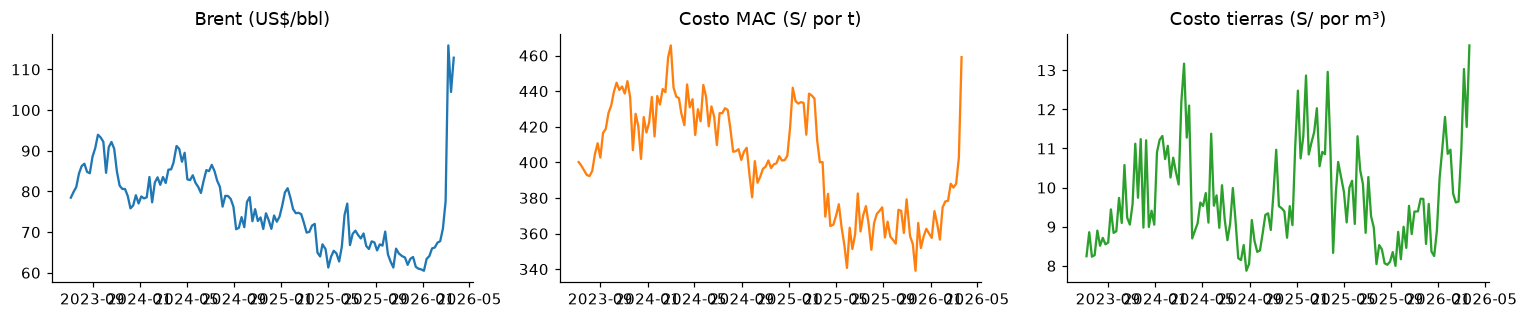

,costo_mac,costo_tierras,precio_ca,brent,fx,diesel,prod_mac,dist_acarreo,utilizacion
costo_mac,1.00,0.33,0.85,0.71,0.68,0.77,-0.33,-0.01,-0.08
costo_tierras,0.33,1.00,0.02,0.24,0.04,0.22,-0.66,0.45,-0.66
precio_ca,0.85,0.02,1.00,0.69,0.83,0.79,0.14,0.05,0.12
brent,0.71,0.24,0.69,1.00,0.46,0.96,-0.03,0.04,0.07
fx,0.68,0.04,0.83,0.46,1.00,0.63,0.15,0.11,0.07
diesel,0.77,0.22,0.79,0.96,0.63,1.00,0.01,0.08,0.07
prod_mac,-0.33,-0.66,0.14,-0.03,0.15,0.01,1.00,0.12,0.51
dist_acarreo,-0.01,0.45,0.05,0.04,0.11,0.08,0.12,1.00,0.00
utilizacion,-0.08,-0.66,0.12,0.07,0.07,0.07,0.51,0.00,1.00


In [18]:
from statsmodels.tsa.stattools import adfuller
filas = []
for c in ["costo_mac", "costo_tierras", "precio_ca", "brent", "fx"]:
    s = df[c]
    filas.append(dict(serie=c, media=s.mean(), de=s.std(), cv=100*s.std()/s.mean(),
                      adf_p_nivel=adfuller(s, autolag="AIC")[1], adf_p_dif=adfuller(np.log(s).diff().dropna(), autolag="AIC")[1]))
display(pd.DataFrame(filas).round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(df.date, df.brent); ax[0].set_title("Brent (US$/bbl)")
ax[1].plot(df.date, df.costo_mac, color="C1"); ax[1].set_title("Costo MAC (S/ por t)")
ax[2].plot(df.date, df.costo_tierras, color="C2"); ax[2].set_title("Costo tierras (S/ por m³)")
plt.tight_layout(); plt.show()
df[["costo_mac", "costo_tierras", "precio_ca", "brent", "fx", "diesel", "prod_mac", "dist_acarreo", "utilizacion"]].corr().round(2)

## 3. Ajuste de hiperparámetros
Búsqueda en rejilla con origen móvil **solo en el periodo de validación** (semanas 61 a 84). El periodo de prueba
no interviene en ninguna decisión. Criterio: pérdida cuantílica media de P10, P50 y P90.

In [19]:
params = {}
for fam in FAMILIAS:
    params[fam], tab = B.ajustar_hiperparametros(df, fam)
    print(fam, params[fam])

costo_mac {'xgb': {'max_depth': 3, 'learning_rate': 0.03, 'n_estimators': 150}, 'lgbm': {'num_leaves': 8, 'learning_rate': 0.03, 'n_estimators': 150, 'min_child_samples': 5}}


costo_tierras {'xgb': {'max_depth': 2, 'learning_rate': 0.1, 'n_estimators': 400}, 'lgbm': {'num_leaves': 8, 'learning_rate': 0.1, 'n_estimators': 300, 'min_child_samples': 10}}


## 4. Validación walk-forward de 12 modelos
Cada semana *t* se reentrena con los objetivos ya observados (semanas ≤ *t* − 4) y se predice el costo medio de
las 4 semanas siguientes. Los intervalos de todos los modelos probabilísticos se calibran con CQR + ACI.

In [20]:
MODELOS = ["ultimo", "pm4", "ets", "sarimax", "arx", "qr", "xgb", "lgbm", "mlp", "lstm", "chronos"]
T, CAL, campeon = [], {}, {}
for fam in FAMILIAS:
    res, tiempos = B.walk_forward(df, fam, MODELOS, params=params[fam])
    tab, CAL[fam] = B.evaluar(res, fam)
    T.append(tab); campeon[fam] = B.elegir_campeon(tab, fam)
    print(fam, "campeón probabilístico / puntual (elegidos en validación):", campeon[fam])
T = pd.concat(T); T["nombre"] = T.modelo.map(NOMBRES)

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 42939.97it/s]

costo_mac campeón probabilístico / puntual (elegidos en validación): ('lgbm', 'sarimax')


costo_tierras campeón probabilístico / puntual (elegidos en validación): ('qr', 'qr')


## 5. Resultados en el periodo de prueba (54 semanas)

In [21]:
cols = ["nombre", "MAE", "MAPE", "MASE", "mejora_MAE", "IC95_inf", "IC95_sup", "p_DM", "p_Holm", "cob_cal", "kupiec_p", "winkler"]
for fam in FAMILIAS:
    print(NOMBRE_FAMILIA[fam]); display(T[(T.familia == fam) & (T.periodo == "prueba")][cols].round(3))

MAC (S/ por t)


,nombre,MAE,MAPE,MASE,mejora_MAE,IC95_inf,IC95_sup,p_DM,p_Holm,cob_cal,kupiec_p,winkler
12,Último costo,11.170,2.977,1.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,Promedio móvil (4 sem.),11.951,3.193,1.070,-6.992,-33.194,15.257,0.660,1.00,NaN,NaN,NaN
14,Suavizamiento exponencial,10.762,2.869,0.964,3.647,-5.937,14.030,0.506,1.00,NaN,NaN,NaN
15,SARIMAX con exógenas,10.578,2.819,0.947,5.297,-2.204,13.405,0.170,1.00,77.778,0.687,57.500
16,ARX (MCO),10.284,2.739,0.921,7.929,-3.003,18.757,0.108,1.00,NaN,NaN,NaN
17,Regresión cuantílica lineal,9.888,2.641,0.885,11.474,-2.319,23.652,0.131,1.00,83.333,0.531,48.708
18,XGBoost cuantílico,10.361,2.767,0.928,7.243,-2.050,14.629,0.170,1.00,81.481,0.783,61.497
19,LightGBM cuantílico,9.902,2.640,0.887,11.345,-2.875,25.331,0.157,1.00,83.333,0.531,63.604
20,Red neuronal MLP cuantílica,10.357,2.773,0.927,7.272,-28.821,33.510,0.717,1.00,88.889,0.080,70.272
21,LSTM cuantílica,10.629,2.852,0.952,4.838,-10.084,13.823,0.547,1.00,88.889,0.080,52.136


Movimiento de tierras (S/ por m³)


,nombre,MAE,MAPE,MASE,mejora_MAE,IC95_inf,IC95_sup,p_DM,p_Holm,cob_cal,kupiec_p,winkler
12,Último costo,0.769,7.743,1.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,Promedio móvil (4 sem.),0.686,7.006,0.891,10.903,-11.564,25.011,0.263,0.790,NaN,NaN,NaN
14,Suavizamiento exponencial,0.674,6.864,0.876,12.447,-6.155,25.322,0.181,0.722,NaN,NaN,NaN
15,SARIMAX con exógenas,0.169,1.669,0.220,78.042,72.621,85.821,0.000,0.000,72.222,0.171,0.900
16,ARX (MCO),0.148,1.488,0.193,80.745,74.696,87.948,0.000,0.000,NaN,NaN,NaN
17,Regresión cuantílica lineal,0.160,1.607,0.208,79.245,72.201,86.901,0.000,0.000,77.778,0.687,1.020
18,XGBoost cuantílico,0.246,2.578,0.320,68.029,54.311,77.932,0.000,0.001,81.481,0.783,1.217
19,LightGBM cuantílico,0.262,2.739,0.340,66.003,51.571,75.412,0.000,0.001,85.185,0.323,1.313
20,Red neuronal MLP cuantílica,0.323,3.402,0.419,58.053,37.124,71.574,0.003,0.015,81.481,0.783,1.233
21,LSTM cuantílica,0.848,9.236,1.103,-10.260,-88.685,28.645,0.754,0.790,83.333,0.531,4.290


In [22]:
# Conjunto de modelos de confianza (Hansen, Lunde y Nason, 2011) al 90 %
for fam in FAMILIAS:
    L = pd.DataFrame({m: np.abs(r.y - r.q50)[r.index >= INICIO_TEST] for m, r in CAL[fam].items()})
    p = pd.Series(M.mcs(L)).sort_values(ascending=False)
    print(NOMBRE_FAMILIA[fam], "→ en el MCS:", list(p[p >= 0.10].index), "| excluidos:", list(p[p < 0.10].index))
    r = CAL[fam][campeon[fam][0]]; b = CAL[fam]["ultimo"]; te = r.index >= INICIO_TEST
    print("   efecto mínimo detectable (80 %% de potencia): %.1f %%" % M.efecto_minimo_detectable((r.y-r.q50)[te].values, (b.y-b.q50)[te].values))

MAC (S/ por t) → en el MCS: ['ens', 'lgbm', 'qr', 'mlp', 'sarimax', 'chronos', 'lstm', 'ets', 'arx', 'pm4', 'xgb'] | excluidos: ['ultimo']
   efecto mínimo detectable (80 % de potencia): 21.0 %
Movimiento de tierras (S/ por m³) → en el MCS: ['arx', 'sarimax', 'ens'] | excluidos: ['qr', 'chronos', 'ultimo', 'ets', 'lgbm', 'xgb', 'lstm', 'mlp', 'pm4']
   efecto mínimo detectable (80 % de potencia): 41.5 %


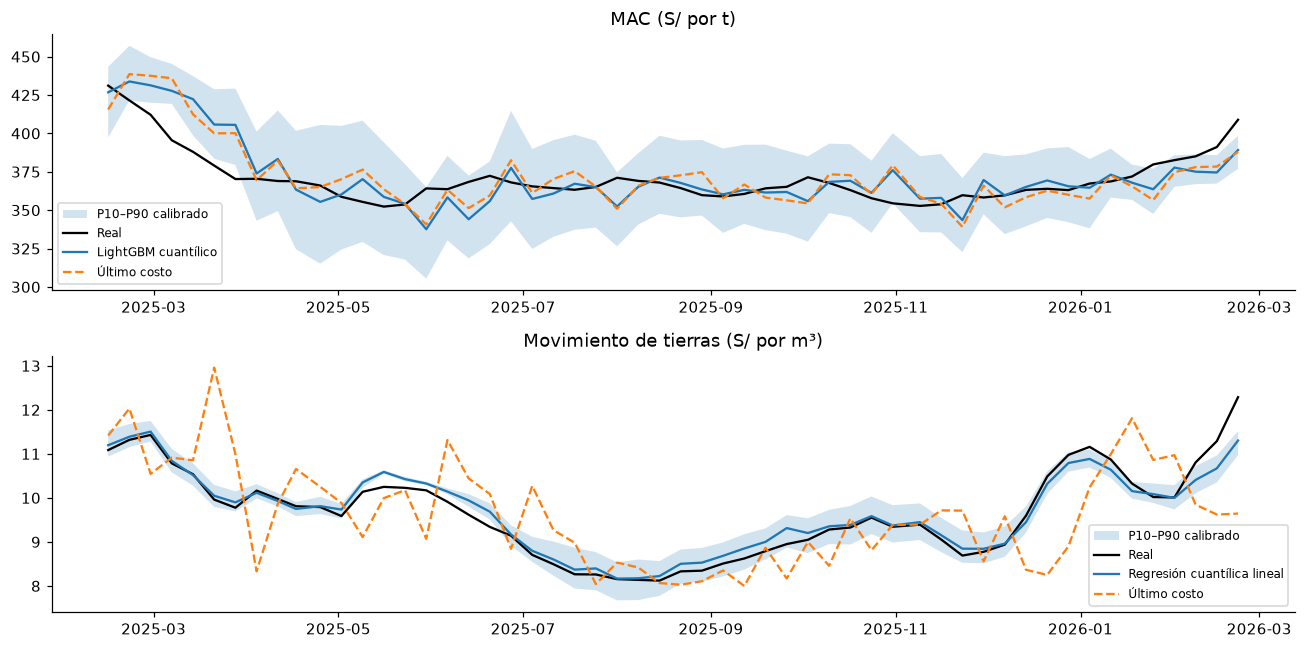

In [23]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6))
for a, fam in zip(axs, FAMILIAS):
    r = CAL[fam][campeon[fam][0]]; te = r[r.index >= INICIO_TEST]; b = CAL[fam]["ultimo"].loc[te.index]
    a.fill_between(te.date, te.lo, te.hi, alpha=0.2, label="P10–P90 calibrado")
    a.plot(te.date, te.y, "k", label="Real"); a.plot(te.date, te.q50, label=NOMBRES[campeon[fam][0]])
    a.plot(te.date, b.q50, "--", label="Último costo"); a.set_title(NOMBRE_FAMILIA[fam]); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Contingencia: práctica actual (último costo + 5 %) frente al motor

In [24]:
cont = {}
for fam in FAMILIAS:
    r = CAL[fam][campeon[fam][0]]
    cont[fam] = C.backtest(r[r.index >= INICIO_TEST], CAL[fam]["ultimo"].q50)
pd.DataFrame(cont).round(3)

,costo_mac,costo_tierras
cont_media_base,5.000,5.000
cont_media_motor,6.903,3.015
cont_min_motor,2.110,1.000
cont_max_motor,14.093,5.945
cobertura_base,90.741,72.222
cobertura_motor,94.444,90.741
deficit_medio_base,0.363,0.237
deficit_medio_motor,0.341,0.023
exceso_medio_base,20.435,0.692
exceso_medio_motor,26.762,0.343


## 7. Ablación y explicabilidad

In [25]:
for fam in FAMILIAS:
    m = campeon[fam][0] if campeon[fam][0] in ("qr", "xgb", "lgbm", "arx") else "xgb"
    Xf = features.construir(df, fam); todas = list(Xf.columns)
    base = B.walk_forward(df, fam, [m], params=params[fam], inicio=INICIO_TEST)[0][m]; mae0 = M.mae(base.y, base.q50)
    out = {}
    for g, cols_g in features.GRUPOS[fam].items():
        rr = B.walk_forward(df, fam, [m], params=params[fam], cols=[c for c in todas if c not in cols_g], inicio=INICIO_TEST)[0][m]
        out[g] = 100 * (M.mae(rr.y, rr.q50) / mae0 - 1)
    print(NOMBRE_FAMILIA[fam], f"({NOMBRES[m]}): aumento del MAE al quitar cada grupo (%)"); display(pd.Series(out).round(1))

MAC (S/ por t) (LightGBM cuantílico): aumento del MAE al quitar cada grupo (%)


Mercado externo (Brent, TC)    19.5
Insumo (cemento asfáltico)      6.3
Planificación (producción)      5.0
Estacionalidad                 -2.1
Autorregresivas (rezagos)       8.3
dtype: float64

Movimiento de tierras (S/ por m³) (Regresión cuantílica lineal): aumento del MAE al quitar cada grupo (%)


Mercado externo (Brent, TC)                       -8.8
Insumo (diésel)                                   97.5
Planificación (acarreo, utilización, lluvias)    218.1
Estacionalidad                                    -3.5
Autorregresivas (rezagos)                          0.0
dtype: float64

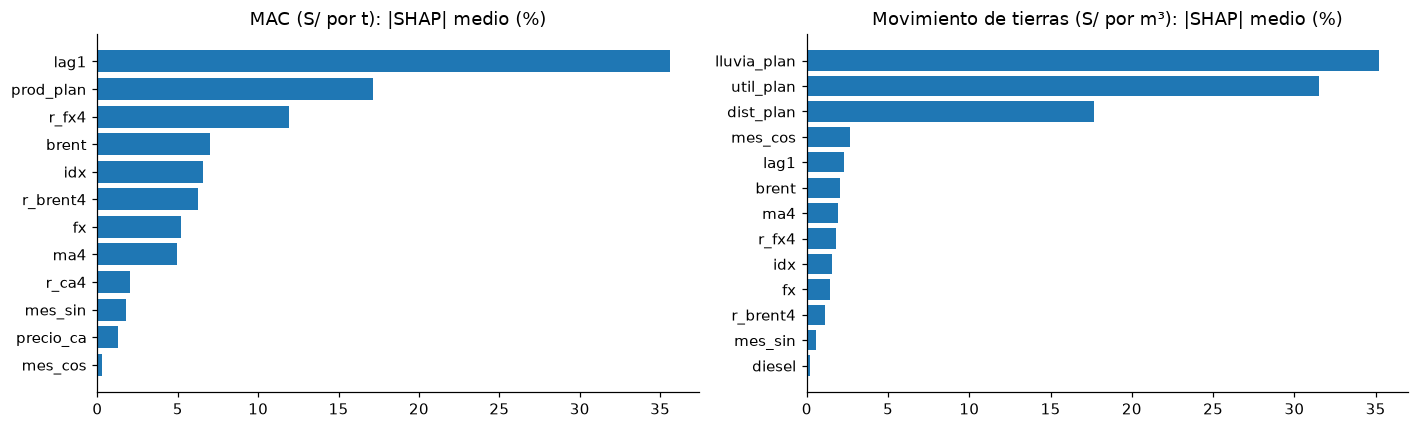

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for a, fam in zip(axs, FAMILIAS):
    Xf, y, z, ref, ok = B.preparar(df, fam)
    idx = [i for i in range(INICIO_TEST - H + 1) if ok.iloc[i]]
    _, sv, _ = X.shap_xgb(Xf.iloc[idx], z.iloc[idx], params[fam]["xgb"])
    imp = sv.abs().mean().sort_values(); a.barh(imp.index, 100 * imp / imp.sum()); a.set_title(f"{NOMBRE_FAMILIA[fam]}: |SHAP| medio (%)")
plt.tight_layout(); plt.show()

## 8. Monitoreo de deriva (PSI y CUSUM)

In [27]:
for fam in FAMILIAS:
    Xf = features.construir(df, fam)
    cols_psi = ["r_brent4", "r_fx4", "r_ca4"] if fam == "costo_mac" else ["r_brent4", "dist_plan", "util_plan"]
    ps = D.psi_movil(Xf[cols_psi], INICIO_TEST)
    rc = CAL[fam][campeon[fam][0]]
    mon = D.monitor_desempeno(rc[rc.index >= INICIO_TEST], errores_ref=(rc.y - rc.q50)[rc.index < INICIO_TEST])
    print(NOMBRE_FAMILIA[fam], "| PSI máximo:", ps.max().round(2).to_dict(), "| alarmas CUSUM:", int(mon.alarma_cusum.sum()),
          "| cobertura móvil mínima: %.0f %%" % mon.cob_movil.min())

MAC (S/ por t) | PSI máximo: {'r_brent4': 0.73, 'r_fx4': 1.11, 'r_ca4': 1.19} | alarmas CUSUM: 2 | cobertura móvil mínima: 58 %
Movimiento de tierras (S/ por m³) | PSI máximo: {'r_brent4': 0.73, 'dist_plan': 1.07, 'util_plan': 0.75} | alarmas CUSUM: 3 | cobertura móvil mínima: 42 %


## 9. Robustez y falsación
Se repite el experimento con otras semillas del generador (escenario base), con el doble de ruido y con costos que
son caminatas aleatorias (falsación: el modelo **no** debe ganar). `REPLICAS = 5` para Colab; el informe usa 20.

In [28]:
REPLICAS = 5
filas = []
for esc in ["base", "ruido_x2", "caminata"]:
    for k in range(REPLICAS):
        d = datos.generar_sintetico(semilla=1000 + k, escenario="caminata" if esc == "caminata" else "base", ruido=2.0 if esc == "ruido_x2" else 1.0)
        for fam in FAMILIAS:
            res, _ = B.walk_forward(d, fam, ["ultimo", "qr", "xgb"], params=params[fam], inicio=INICIO_TEST)
            for m in ["qr", "xgb"]:
                filas.append(dict(escenario=esc, familia=fam, modelo=m, mejora=100 * (1 - M.mae(res[m].y, res[m].q50) / M.mae(res["ultimo"].y, res["ultimo"].q50))))
pd.DataFrame(filas).groupby(["escenario", "familia", "modelo"]).mejora.describe()[["mean", "min", "max"]].round(1)

mean    min   max
escenario familia       modelo                    
base      costo_mac     qr        5.9   -3.1  12.6
                        xgb       5.1   -0.6  10.2
          costo_tierras qr       76.1   72.2  79.8
                        xgb      55.1   46.5  64.5
caminata  costo_mac     qr        3.3   -5.1   8.6
                        xgb      -6.2  -12.5  -1.2
          costo_tierras qr     -162.8 -265.1 -90.8
                        xgb     -46.6  -98.6  -7.7
ruido_x2  costo_mac     qr        0.0   -5.5   5.1
                        xgb       8.3    2.6  11.6
          costo_tierras qr       70.9   64.1  76.0
                        xgb      49.5   30.0  61.7

**Permutación de la información explicativa.** Se barajan en el tiempo, en bloque, las variables externas, de insumo y
de planificación; si la ventaja proviene de información legítima, debe desaparecer (el informe usa 20 permutaciones).

In [29]:
COLS = ["brent", "fx", "precio_ca", "diesel", "dist_acarreo_plan", "utilizacion_plan", "lluvia_plan", "prod_plan"]
filas = []
for k in range(5):
    d = df.copy(); idx = np.random.default_rng(500 + k).permutation(len(d)); d[COLS] = d[COLS].values[idx]
    for fam in FAMILIAS:
        res, _ = B.walk_forward(d, fam, ["ultimo", "qr"], params=params[fam], inicio=INICIO_TEST)
        filas.append(dict(familia=fam, mejora=100 * (1 - M.mae(res["qr"].y, res["qr"].q50) / M.mae(res["ultimo"].y, res["ultimo"].q50))))
pd.DataFrame(filas).groupby("familia").mejora.describe()[["mean", "min", "max"]].round(1)

,mean,min,max
familia,,,
costo_mac,-6.6,-11.2,0.1
costo_tierras,31.2,28.3,35.9


## 10. Análisis económico (VAN, TIR, B/C y Monte Carlo)

,Pesimista,Base,Optimista,Sin competitividad
VAN,-27172.49,310630.22,718330.73,59948.23
TIR,1.44,129.27,253.18,38.89
BC,0.89,2.65,4.82,1.32
recuperacion,NaN,1.10,0.57,2.06


Monte Carlo: {'prob_van_pos': 97.0, 'p5': 15835.8, 'p50': 203617.5, 'p95': 559632.1, 'media': 235009.0}


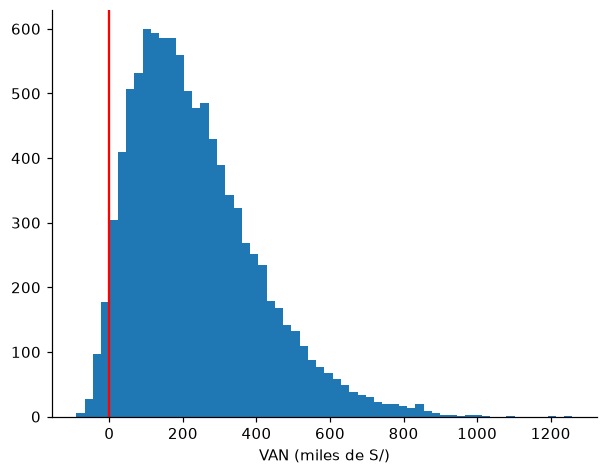

In [30]:
esc = E.escenarios(cont)
display(pd.DataFrame({k: dict(VAN=v["VAN"], TIR=100 * v["TIR"], BC=v["BC"], recuperacion=v["recuperacion"]) for k, v in esc.items()}).round(2))
mc, vans = E.montecarlo(cont)
print("Monte Carlo:", {k: round(v, 1) for k, v in mc.items()})
plt.hist(vans / 1000, bins=60); plt.axvline(0, color="r"); plt.xlabel("VAN (miles de S/)"); plt.show()

## Conclusión del cuaderno
Los resultados numéricos de este cuaderno coinciden con los del informe cuando se usan los datos sintéticos con la
semilla 2026. Con el historial real del ERP, basta con definir `RUTA_ERP` y ejecutar todo de nuevo: el diseño de
validación, la selección del campeón y las pruebas no cambian.